# Solutions to the exercises of Chapter 9

Sample solutions for [Chapter 9, Natural convection](../../notebooks/part2_convection/09_natural_convection.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import natural_conv, properties
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import natural_conv, properties
from engtransport.constants import SIGMA_SB
from engtransport.plotting import use_style

use_style()
g = 9.81


def rayleigh(T_s, T_inf, L):
    air = properties.dry_air_properties(0.5 * (T_s + T_inf))
    return g * air["beta"] * abs(T_s - T_inf) * L**3 / (air["nu"] * air["alpha"]), air

## Exercise 1. The sun on the cabinet

The sunlight absorbed by the walls must leave through them as well, so with the walls at
50 °C it takes its share of the 623 W found in Section 9.4. The absorbed power is
$\alpha_s(G_{top}A_{top} + G_{side}A_{side,1})$.

In [2]:
A_top, A_one_side = 0.6 * 0.6, 0.6 * 1.6
Q_walls = 623.0                                    # W, Section 9.4, walls at 50 C in 35 C air
for name, alpha_s in (("grey paint", 0.60), ("white paint", 0.25)):
    Q_sun = alpha_s * (900.0 * A_top + 500.0 * A_one_side)
    print(f"{name}: sunlight absorbed {Q_sun:.0f} W, left for the electronics {Q_walls - Q_sun:.0f} W")

grey paint: sunlight absorbed 482 W, left for the electronics 141 W
white paint: sunlight absorbed 201 W, left for the electronics 422 W


The grey cabinet absorbs 480 W of sunlight, three quarters of what its walls can shed, and
only 140 W remains for the electronics. White paint, which reflects most sunlight but
emits as well as grey in the infrared, absorbs 200 W and leaves 420 W. This is why
outdoor cabinets are white and often carry a separate sun shield with an air gap: the
shield takes the sunlight, and the cabinet sees a surface near the air temperature. The
calculation is rough: the sunlit walls are hotter than the shaded ones, and in reality
the limit applies to the hottest wall.

## Exercise 2. A radiator that mostly convects

In [3]:
H, W, T_s, T_room, T_walls, eps = 0.6, 1.0, 273.15 + 60.0, 273.15 + 20.0, 273.15 + 18.0, 0.9
Ra, air = rayleigh(T_s, T_room, H)
Nu = natural_conv.nu_vertical_plate_churchill_chu_laminar(Ra, air["Pr"])
h = Nu * air["k"] / H
Q_conv = 2 * H * W * h * (T_s - T_room)
Q_rad = H * W * eps * SIGMA_SB * (T_s**4 - T_walls**4)
print(f"Ra = {Ra:.2e} (laminar), h = {h:.2f} W/(m2 K)")
print(f"convection from both faces {Q_conv:.0f} W, radiation from the front {Q_rad:.0f} W;"
      f" total {Q_conv + Q_rad:.0f} W, {100 * Q_rad / (Q_conv + Q_rad):.0f} % by radiation")

Ra = 6.61e+08 (laminar), h = 3.79 W/(m2 K)
convection from both faces 182 W, radiation from the front 157 W; total 339 W, 46 % by radiation


The layer is laminar ($\mathrm{Ra} = 6.6 \times 10^8$). The panel gives about 340 W, of
which less than half, 46 %, is radiation: the "radiator" convects as much as it radiates,
because both faces convect while only the front radiates to the room. Ribbed convector
fins welded to the back of modern panels push the share of convection further.

## Exercise 3. Water against air

In [4]:
L, dT = 0.1, 10.0
fluids = {
    "water": {"k": 0.607, "nu": 8.9e-7, "Pr": 6.1, "beta": 2.6e-4},
}
_, air = rayleigh(273.15 + 30.0, 273.15 + 20.0, L)
fluids["air"] = {"k": air["k"], "nu": air["nu"], "Pr": air["Pr"], "beta": air["beta"]}
for name, f in fluids.items():
    Gr = g * f["beta"] * dT * L**3 / f["nu"] ** 2
    sim = natural_conv.free_convection_similarity(f["Pr"])
    h_sim = (4 / 3) * sim["G"] * (Gr / 4) ** 0.25 * f["k"] / L
    h_cc = natural_conv.nu_vertical_plate_churchill_chu_laminar(Gr * f["Pr"], f["Pr"]) * f["k"] / L
    eta_99 = sim["eta"][np.nonzero(sim["theta"] > 0.01)[0][-1] + 1]
    delta_T = eta_99 * L * (Gr / 4) ** -0.25
    print(f"{name}: Gr = {Gr:.2e}, Ra = {Gr * f['Pr']:.2e}; mean h = {h_sim:.1f} (similarity), {h_cc:.1f} W/(m2 K) (Eq. 9.7);"
          f" thermal layer at the top {1000 * delta_T:.1f} mm")

water: Gr = 3.22e+07, Ra = 1.96e+08; mean h = 436.4 (similarity), 441.3 W/(m2 K) (Eq. 9.7); thermal layer at the top 3.5 mm


air: Gr = 1.35e+06, Ra = 9.58e+05; mean h = 4.2 (similarity), 4.4 W/(m2 K) (Eq. 9.7); thermal layer at the top 18.5 mm


In water the plate has a mean $h$ of about 440 W/(m² K), a hundred times more than in air
(4.2 W/(m² K)), and a thermal layer of only 3.5 mm against 18.5 mm. Water conducts 23
times better, its ratio $\beta/\nu^2$, which sets the Grashof number, is 24 times larger,
and its larger Prandtl number thins the thermal layer. The similarity value and Eq. (9.7)
differ by 1 % in water and 5 % in air: the correlation's constant 0.68 adds the edge
effects, which matter more at the smaller Rayleigh number of air.

## Exercise 4. How fast does the air rise?

x = 0.1 m: Gr = 1.57e+06; largest velocity 0.12 m/s, velocity layer 23 mm; Gr/Re^2 for a 0.5 m/s breeze = 0.19
x = 0.5 m: Gr = 1.96e+08; largest velocity 0.27 m/s, velocity layer 34 mm; Gr/Re^2 for a 0.5 m/s breeze = 0.93


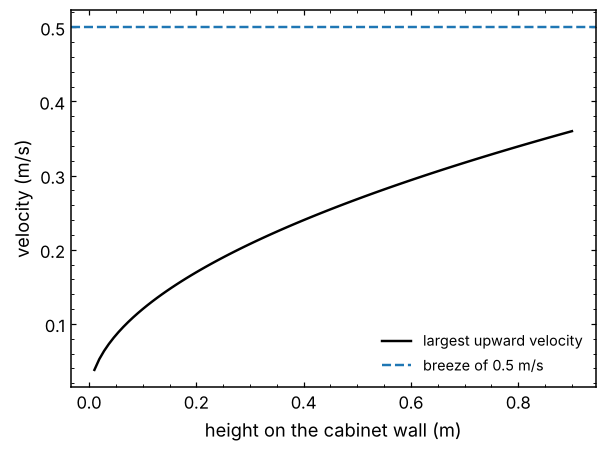

In [5]:
T_w, T_inf = 273.15 + 50.0, 273.15 + 35.0
air = properties.dry_air_properties(0.5 * (T_w + T_inf))
sim = natural_conv.free_convection_similarity(air["Pr"])
i_max = int(np.argmax(sim["Fp"]))
eta_v = sim["eta"][i_max + np.nonzero(sim["Fp"][i_max:] < 0.01 * sim["Fp"][i_max])[0][0]]
for x in (0.1, 0.5):
    Gr = g * air["beta"] * (T_w - T_inf) * x**3 / air["nu"] ** 2
    u_max = 2 * air["nu"] / x * Gr**0.5 * sim["Fp"][i_max]
    delta_v = eta_v * x * (Gr / 4) ** -0.25
    ratio = Gr / (0.5 * x / air["nu"]) ** 2
    print(f"x = {x} m: Gr = {Gr:.2e}; largest velocity {u_max:.2f} m/s, velocity layer {1000 * delta_v:.0f} mm;"
          f" Gr/Re^2 for a 0.5 m/s breeze = {ratio:.2f}")

xs = np.linspace(0.01, 0.9, 100)
Grs = g * air["beta"] * (T_w - T_inf) * xs**3 / air["nu"] ** 2
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(xs, 2 * air["nu"] / xs * Grs**0.5 * sim["Fp"][i_max], "k-", label="largest upward velocity")
ax.axhline(0.5, color="C0", ls="--", label="breeze of 0.5 m/s")
ax.set_xlabel("height on the cabinet wall (m)")
ax.set_ylabel("velocity (m/s)")
ax.legend(loc="lower right")
plt.show()

**Figure S9.1.** Largest upward velocity in the laminar layer on the cabinet wall (walls at
50 °C, air at 35 °C), against height, with a breeze of 0.5 m/s for comparison.

The air rises at 0.12 m/s at 0.1 m and 0.27 m/s at 0.5 m, growing as $x^{1/2}$, like the
speed of a fall through $x$ under the reduced gravity $g\beta\Delta T$. The velocity layer
is 2.3 cm thick at 0.1 m and 3.4 cm at 0.5 m, wider than the thermal layer because the
rising fluid drags its neighbours along. A breeze of 0.5
m/s blowing up the wall has $\mathrm{Gr}_x/\mathrm{Re}_x^2 = 0.19$ at 0.1 m and 0.93 at
0.5 m: buoyancy and the breeze are comparable over the whole wall, and neither formula
alone is right. Only for $\mathrm{Gr}/\mathrm{Re}^2 \ll 1$ does forced convection take over,
which for this wall means winds of a metre per second or more.